In [ ]:
%pip install matplotlib seaborn numpy pandas torch datasets transformers

In [13]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

import time
import copy
import gc
from tqdm import tqdm

import matplotlib.pyplot as plt
import seaborn as sns
import random
import numpy as np
import pandas as pd

import torch
import torch.nn as nn

from utils import get_opt, get_loaders, eval_ppl

In [3]:
DEV = torch.device('cuda:0') if torch.cuda.is_available() else torch.device('cpu')

seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

# Load

## Model

In [39]:
# model_name = "HuggingFaceTB/SmolLM2-135M"
model_name = "HuggingFaceTB/SmolLM2-1.7B"

model = get_opt(model_name)
model.eval()
model.to(DEV)

LlamaForCausalLM(
  (model): LlamaModel(
    (embed_tokens): Embedding(49152, 2048)
    (layers): ModuleList(
      (0-23): 24 x LlamaDecoderLayer(
        (self_attn): LlamaAttention(
          (q_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (k_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (v_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (o_proj): Linear(in_features=2048, out_features=2048, bias=False)
        )
        (mlp): LlamaMLP(
          (gate_proj): Linear(in_features=2048, out_features=8192, bias=False)
          (up_proj): Linear(in_features=2048, out_features=8192, bias=False)
          (down_proj): Linear(in_features=8192, out_features=2048, bias=False)
          (act_fn): SiLU()
        )
        (input_layernorm): LlamaRMSNorm((2048,), eps=1e-05)
        (post_attention_layernorm): LlamaRMSNorm((2048,), eps=1e-05)
      )
    )
    (norm): LlamaRMSNorm((2048,), eps=1e-05)
    (rotary_emb)

## Datasets

In [5]:
n_samples = 32

dataloader, testloader = get_loaders(
    "c4", nsamples=n_samples, seed=0, model=model_name, seqlen=model.seqlen
)

Token indices sequence length is longer than the specified maximum sequence length for this model (8597 > 8192). Running this sequence through the model will result in indexing errors


In [6]:
wiki_dataloader, wiki_testloader = get_loaders(
    'wikitext2', seed=0, model=model_name, seqlen=model.seqlen
)

Token indices sequence length is longer than the specified maximum sequence length for this model (2565857 > 8192). Running this sequence through the model will result in indexing errors


ts torch.Size([1, 2565857])



---
# Iterative layer pruning


In [18]:
class SkipMLP(nn.Module):
    def forward(self, x):
        return torch.zeros_like(x, device=DEV)

In [25]:
@torch.no_grad()
def prune_model():
    layer_ids = set(range(len(model.model.layers)))
    pruned_ids = set()
    pruned_layers = dict()
    layer_order = []
    for i in range(len(layer_ids)):
        # find the best candidate to prune next
        best_candidate = None
        best_candidate_ppl = float('inf')

        # iterate over the remaining layers
        candidate_blocks = layer_ids - pruned_ids 
        
        for block_id in candidate_blocks:
            print(block_id, end=' ')
            # try pruning the layer, keep its copy in the dict
            if block_id not in pruned_layers:
                pruned_layers[block_id] = copy.deepcopy(model.model.layers[block_id].mlp)
            model.model.layers[block_id].mlp = SkipMLP()
            # evaluate ppl
            candidate_ppl = eval_ppl(model, testloader, device=DEV)
            if candidate_ppl < best_candidate_ppl:
                best_candidate_ppl = candidate_ppl
                best_candidate = block_id
            # revert changes
            model.model.layers[block_id].mlp = copy.deepcopy(pruned_layers[block_id])
        print()
        # prune the least important layer
        if best_candidate is not None:
            pruned_ids.add(best_candidate)
            layer_order.append(best_candidate)
            model.model.layers[best_candidate].mlp = SkipMLP()
            current_ppl = best_candidate_ppl
            print(f'pruned layer: {best_candidate}\tcurrent ppl: {best_candidate_ppl}')
    return layer_order


In [26]:
layer_order = prune_model()

0 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 
pruned layer: 12	current ppl: 12.387331008911133
1 2 3 4 5 6 7 8 9 10 11 13 14 15 16 17 18 19 20 21 22 23 
pruned layer: 5	current ppl: 13.274182319641113
1 2 3 4 6 7 8 9 10 11 13 14 15 16 17 18 19 20 21 22 23 
pruned layer: 13	current ppl: 14.386321067810059
1 2 3 4 6 7 8 9 10 11 14 15 16 17 18 19 20 21 22 23 
pruned layer: 21	current ppl: 16.243019104003906
1 2 3 4 6 7 8 9 10 11 14 15 16 17 18 19 20 22 23 
pruned layer: 10	current ppl: 18.66510581970215
1 2 3 4 6 7 8 9 11 14 15 16 17 18 19 20 22 23 
pruned layer: 15	current ppl: 22.352231979370117
1 2 3 4 6 7 8 9 11 14 16 17 18 19 20 22 23 
pruned layer: 9	current ppl: 27.389720916748047
1 2 3 4 6 7 8 11 14 16 17 18 19 20 22 23 
pruned layer: 20	current ppl: 33.786312103271484
1 2 3 4 6 7 8 11 14 16 17 18 19 22 23 
pruned layer: 19	current ppl: 49.43471145629883
1 2 3 4 6 7 8 11 14 16 17 18 22 23 
pruned layer: 8	current ppl: 78.06245422363281
1 2 3 4 6 7 11 14 16 17 18 2

In [27]:
layer_order

[12,
 5,
 13,
 21,
 10,
 15,
 9,
 20,
 19,
 8,
 2,
 18,
 17,
 14,
 16,
 3,
 23,
 4,
 1,
 22,
 11,
 6,
 0,
 7]

In [72]:
bp_importance = pd.Series(
    {i: rank for rank, i in enumerate(block_pruner_order['MLP_id'])},
    name='importance'
).sort_index().to_frame()
bp_importance.to_csv('block_pruner_importance.csv')
bp_importance

,importance
0,22
1,18
2,10
3,15
4,17
5,1
6,21
7,23
8,9
9,6


In [28]:
block_pruner_order = pd.DataFrame(layer_order, columns=["MLP_id"])
block_pruner_order.to_csv('block_pruner_order.csv')

In [29]:
block_pruner_order = pd.read_csv('block_pruner_order.csv', index_col=0)
layer_order = block_pruner_order['MLP_id'].to_list()

---
# Layer-Skipping Strategies

## Removing layers from the least significant

In [40]:
results_block_pruner = pd.DataFrame(columns=["perplexity"])

num_skipped = 0
skipped = {}

ppl = eval_ppl(model, wiki_testloader, device=DEV)
results_block_pruner.loc[num_skipped] = [ppl]
print(f'ppl {ppl}\n')

for i in layer_order:
    gc.collect()
    torch.cuda.empty_cache()

    num_skipped += 1
    skipped[i] = copy.deepcopy(model.model.layers[i].mlp)
    model.model.layers[i].mlp = SkipMLP()
    print(f'skipped MLPs {num_skipped} {list(skipped.keys())}')

    ppl = eval_ppl(model, wiki_testloader, device=DEV)
    results_block_pruner.loc[num_skipped] = [ppl]
    print(f'ppl {ppl}\n')

    if ppl > 1e4: break

results_block_pruner.to_csv('results_block_pruner.csv')
results_block_pruner

ppl 7.260688781738281

skipped MLPs 1 [12]
ppl 7.6639604568481445

skipped MLPs 2 [12, 5]
ppl 8.320028305053711

skipped MLPs 3 [12, 5, 13]
ppl 9.105021476745605

skipped MLPs 4 [12, 5, 13, 21]
ppl 10.508621215820312

skipped MLPs 5 [12, 5, 13, 21, 10]
ppl 12.479296684265137

skipped MLPs 6 [12, 5, 13, 21, 10, 15]
ppl 16.255462646484375

skipped MLPs 7 [12, 5, 13, 21, 10, 15, 9]
ppl 19.33647346496582

skipped MLPs 8 [12, 5, 13, 21, 10, 15, 9, 20]
ppl 24.361154556274414

skipped MLPs 9 [12, 5, 13, 21, 10, 15, 9, 20, 19]
ppl 36.201656341552734

skipped MLPs 10 [12, 5, 13, 21, 10, 15, 9, 20, 19, 8]
ppl 65.85794067382812

skipped MLPs 11 [12, 5, 13, 21, 10, 15, 9, 20, 19, 8, 2]
ppl 125.77061462402344

skipped MLPs 12 [12, 5, 13, 21, 10, 15, 9, 20, 19, 8, 2, 18]
ppl 238.16717529296875

skipped MLPs 13 [12, 5, 13, 21, 10, 15, 9, 20, 19, 8, 2, 18, 17]
ppl 570.85107421875

skipped MLPs 14 [12, 5, 13, 21, 10, 15, 9, 20, 19, 8, 2, 18, 17, 14]
ppl 1091.0902099609375

skipped MLPs 15 [12, 5, 13, 2

,perplexity
0,7.260689
1,7.663960
2,8.320028
3,9.105021
4,10.508621
5,12.479297
6,16.255463
7,19.336473
8,24.361155
9,36.201656


## Results

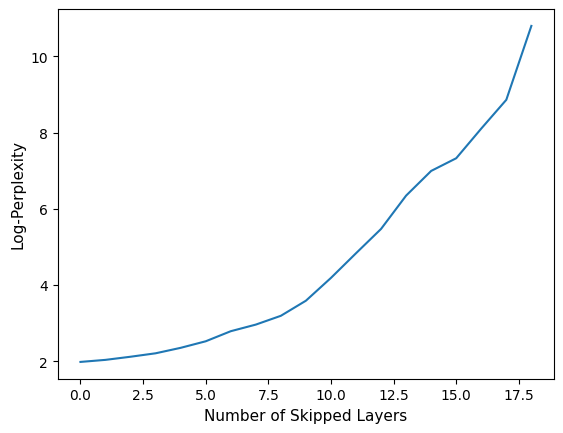

In [41]:
results_block_pruner['log_perplexity'] = np.log(results_block_pruner.perplexity)
plt.plot(results_block_pruner.log_perplexity)
plt.xlabel('Number of Skipped Layers', fontsize=11)
plt.ylabel('Log-Perplexity', fontsize=11);

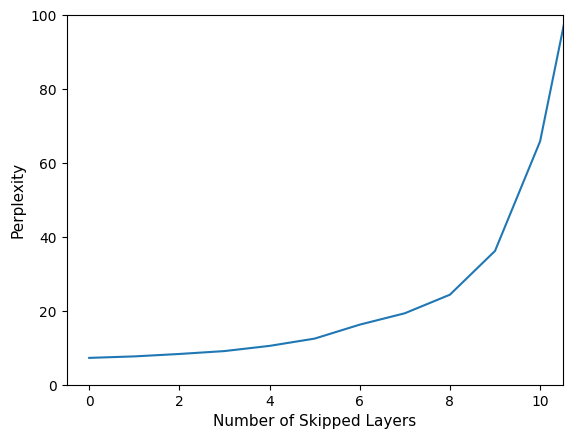

In [49]:
plt.plot(results_block_pruner.perplexity)
plt.xlabel('Number of Skipped Layers', fontsize=11)
plt.ylabel('Perplexity', fontsize=11);
plt.ylim((0, 100))
plt.xlim((-0.5, 10.5));